## **XG Boost** ##
The aim for introducing Random Forest (Regressor) to the project is to **predict future number of influenza case detections** with the obtained data. The difference with it and Random FOrest is that XGBoost construct the next tree based on the performance of the previous tree. It is not primarily chosen because of its higher complexity and longer execution time comparing to Random Forest. 

---

In [1]:
import pandas as pd 
import numpy as np

from scipy.stats import randint, uniform
from xgboost import XGBRegressor
import xgboost as xgbl
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV, TimeSeriesSplit
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score, accuracy_score

import graphviz
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv("data_engineed.csv")
df["From"] = pd.to_datetime(df["From"])
df = df.sort_values("From").reset_index(drop=True)

In [3]:
mete_col = ["Diurnal temperature range (°C)", "Mean temperature (°C)", "Mean humidity (%)", "Solar radiation (MJ/m²)", "Air pressure (hPa)", "Dew point temperature (°C)", "Wind speed (km/h)", "Mean UV"]
# flu_col = ["H1", "H3", "B", "AandB"]
flu_col = ["H1", "H3", "AandB"]

---

In [4]:
grid = {
    "n_estimators": [x for x in range(100, 1000, 100)],
    "learning_rate": uniform(0.01, 0.20), 
    "max_depth": [x for x in range(3, 9)], 
    "subsample": uniform(0.6, 0.4),
    "colsample_bytree": uniform(0.6, 0.4),
    "min_child_weight": randint(10, 30),
    "reg_alpha": uniform(0, 5), 
    "reg_lambda": uniform(1, 10)
}

In [ ]:
for col in flu_col: 
    tmp_df = df.copy()

    # Seperate case for type AH1 influenza
    if col == "H1":
        for n in range(4):
            tmp_df[f"{col}_Lag{n+1}"] = tmp_df[col].shift(n+1)
        tmp_df[f"{col}_volatility"] = tmp_df[col].shift(1).rolling(window=4).std()
        tmp_df[f"{col}_rolling_mean"] = tmp_df[col].shift(1).rolling(window=4).mean()
    else:
        for n in range(2):
            tmp_df[f"{col}_Lag{n+1}"] = tmp_df[col].shift(n+1)
        tmp_df[f"{col}_volatility"] = tmp_df[col].shift(1).rolling(window=4).std()
        tmp_df[f"{col}_rolling_mean"] = tmp_df[col].shift(1).rolling(window=4).mean()

    tmp_df = tmp_df.dropna().reset_index(drop=True)

    X = tmp_df.drop(columns=["From"]+flu_col)


    print(f"{'='*70} {col} {'='*70}")
    y = tmp_df[col]

    train_end = int(tmp_df.shape[0] * 0.8)
    X_train, X_test = X.iloc[:train_end], X.iloc[train_end:]
    y_train, y_test = y.iloc[:train_end], y.iloc[train_end:]

    y_train_log = np.log1p(y_train)

    tscv = TimeSeriesSplit(n_splits=5)
    xgb = XGBRegressor(random_state=42)
    xgb_cv = RandomizedSearchCV(estimator=xgb, param_distributions=grid, cv=tscv, scoring="roc_auc", n_jobs=-1)

    xgb_cv.fit(X_train, y_train_log)

    print(f"Best Parameters: {xgb_cv.best_params_}")
    print("Best CV Score:", xgb_cv.best_score_)

    print(f"\nFeature importances: ")
    model = xgb_cv.best_estimator_
    importance = pd.Series(model.feature_importances_, index=X.columns)
    print(importance.sort_values(ascending=False))

    model.fit(X_train, y_train_log)
    
    # Evaluation
    y_pred_log = model.predict(X_train)
    y_pred = np.expm1(y_pred_log)
    print(f"\nModel metrics with train data: ")
    print(f"MAE: {mean_absolute_error(y_train, y_pred):.4f}")
    print(f"MSE: {mean_squared_error(y_train, y_pred):.4f}")
    print(f"R2:  {r2_score(y_train, y_pred):.4f}")

    y_pred_log = model.predict(X_test)
    y_pred = np.expm1(y_pred_log)
    print(f"\nModel metrics with test data: ")
    print(f"MAE: {mean_absolute_error(y_test, y_pred):.4f}")
    print(f"MSE: {mean_squared_error(y_test, y_pred):.4f}")
    print(f"R2:  {r2_score(y_test, y_pred):.4f}")
    

====================================================================== H1 ======================================================================


c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Parameters: {'colsample_bytree': np.float64(0.8461451649986085), 'learning_rate': np.float64(0.024158603515459613), 'max_depth': 8, 'min_child_weight': 26, 'n_estimators': 900, 'reg_alpha': np.float64(1.1225267271077972), 'reg_lambda': np.float64(7.191225105543525), 'subsample': np.float64(0.6752824563716598)}
Best CV Score: nan

Feature importances: 
H1_Lag1                           0.527351
H1_rolling_mean                   0.261190
H1_Lag2                           0.086567
pandemic_flag                     0.018461
H1_volatility                     0.013822
H1_Lag4                           0.008402
Mean temperature (°C)             0.006984
ContainmentHealthIndex_Average    0.006790
Dew point temperature (°C)        0.006546
Week                              0.006471
H1_Lag3                           0.006469
B                                 0.006259
Year                              0.005940
Population                        0.005454
Wind speed (km/h)                 0.005

c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Parameters: {'colsample_bytree': np.float64(0.9250712105332429), 'learning_rate': np.float64(0.055902711970215985), 'max_depth': 8, 'min_child_weight': 21, 'n_estimators': 800, 'reg_alpha': np.float64(2.3543086414174534), 'reg_lambda': np.float64(9.609944092141525), 'subsample': np.float64(0.9191280566577611)}
Best CV Score: nan

Feature importances: 
H3_Lag1                           0.835841
H3_Lag2                           0.065095
pandemic_flag                     0.021524
H3_rolling_mean                   0.019987
H3_volatility                     0.006672
Year                              0.006071
Week                              0.005210
B                                 0.004456
Population                        0.004204
Dew point temperature (°C)        0.003920
Air pressure (hPa)                0.003778
ContainmentHealthIndex_Average    0.003660
Mean temperature (°C)             0.003639
Solar radiation (MJ/m²)           0.002910
Mean humidity (%)                 0.002

c:\Users\yanss\anaconda3\Lib\site-packages\sklearn\model_selection\_search.py:1135: UserWarning: One or more of the test scores are non-finite: [nan nan nan nan nan nan nan nan nan nan]
  warnings.warn(


Best Parameters: {'colsample_bytree': np.float64(0.8317519494291343), 'learning_rate': np.float64(0.09297242839034878), 'max_depth': 6, 'min_child_weight': 13, 'n_estimators': 100, 'reg_alpha': np.float64(2.557408338144016), 'reg_lambda': np.float64(7.581570961103288), 'subsample': np.float64(0.8461068029132136)}
Best CV Score: nan

Feature importances: 
AandB_Lag1                        0.727347
AandB_Lag2                        0.064013
Year                              0.058611
ContainmentHealthIndex_Average    0.057401
AandB_rolling_mean                0.038047
B                                 0.014150
AandB_volatility                  0.009085
pandemic_flag                     0.004628
Mean temperature (°C)             0.004039
Air pressure (hPa)                0.003413
Week                              0.003099
Dew point temperature (°C)        0.002591
school_flag                       0.002550
Population                        0.002322
Diurnal temperature range (°C)    0.00209

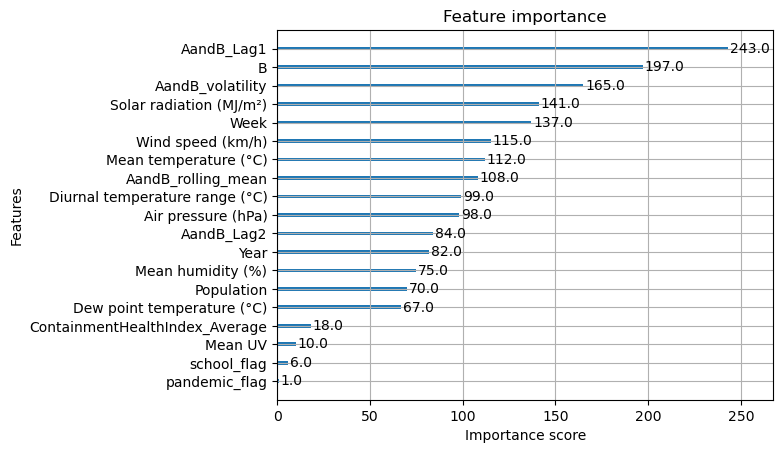

In [6]:
xgbl.plot_importance(model)
plt.show()

In [7]:
# xgbl.plot_tree(model, num_tree=2)

---
**Interpretation**